# Initial Value Problem: Predator-Prey Dynamics

This notebook studies the **Lotka-Volterra system**, a classical example of an initial value problem (cf. Section 2.2), and constructs surrogate models for its solution operator.

### The model

The Lotka-Volterra equations describe the interaction between a prey population and a predator population.
The state of the system at time $t$ is
$$
  \mathbf{u}(t) = (u_1(t), u_2(t))^\top,
$$
where $u_1(t)$ denotes the prey population size and $u_2(t)$ the predator population size.

Their evolution is governed by the system of ordinary differential equations
$$
  \dot{u}_1 = \alpha u_1 - \beta u_1 u_2, \qquad
  \dot{u}_2 = \delta u_1 u_2 - \gamma u_2.
$$
Here, $\alpha$ is the prey birth rate, $\beta$ the predation rate, $\gamma$ the predator death rate, and $\delta$ the predator growth rate per consumed prey.

Given an initial condition $\mathbf{u}(0) = \mathbf{u}_0 \in \mathbb{R}^2$, this defines a unique trajectory $\mathbf{u}(t)$.

### Solution operator

Rather than focusing on the full trajectory, we consider the map that assigns to each initial condition its state at a fixed time $T > 0$. This defines the **solution operator**
$$
  S(T) : \mathbb{R}^2 \to \mathbb{R}^2, \qquad \mathbf{u}_0 \mapsto \mathbf{u}(T).
$$

### Parameter domain

To obtain a well-structured approximation problem, we restrict the initial data to a compact set around the system's equilibrium
$$
  \mathbf{u}_* = \left(\frac{\gamma}{\delta}, \frac{\alpha}{\beta}\right).
$$
Specifically, we consider
$$
  K = \mathbf{u}_* + r[-1,1]^2,
$$
and parametrise initial conditions by $\bar{\mathbf{x}} \in [-1,1]^2$ via
$$
  \mathbf{u}_0 = \mathbf{u}_* + r\bar{\mathbf{x}}.
$$

### Goal

The goal of this notebook is to approximate the solution operator $S(T)$ on $K$ and to compare sparse-grid interpolation with feedforward networks as two alternative surrogate modelling approaches.

In [1]:
import time
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 12})

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import jax
jax.config.update('jax_platform_name', 'cpu')

from smolyax import indices, nodes
from smolyax.interpolation import SmolyakBarycentricInterpolator

import error

from importer import import_notebook
import_notebook('3_PCANet.ipynb', globals())  # FFN

In [2]:
# Predator-Prey parameters
alpha = 1.5     # prey birth rate
beta  = 1.0     # predation rate
gamma = 0.75    # predator death rate
delta = 1.0     # predator growth rate per prey eaten
T     = 3.0     # time horizon
r     = 0.5     # perturbation radius around the equilibrium

# Surrogate parameters
n_max    = 1000     # maximum number of training samples
n_test   = 200      # test samples
n_epochs = 500      # training epochs
layers   = [32, 32] # hidden layer widths

rng = np.random.default_rng(0)

## 1. The Lotka-Volterra System

The system has a unique positive equilibrium at $\mathbf{u}_* = (\gamma/\delta, \alpha/\beta)$.
From any nearby initial condition the trajectory orbits $\mathbf{u}_*$ periodically; the period
grows with the distance from equilibrium.

The right-hand side $\Phi(\mathbf{u}) = (\alpha u_1 - \beta u_1 u_2, \delta u_1 u_2 - \gamma u_2)^\top$
is a polynomial in $\mathbf{u}$, hence real-analytic on $\mathbb{R}^2$.
Theorem 2.4 therefore implies that the solution map $S(T)$ is real-analytic on every
compact $K \subset \mathbb{R}^2_{>0}.$

In [3]:
class LotkaVolterra:

    def __init__(self, *, alpha=1.5, beta=1.0, gamma=0.75, delta=1.0, T=3.0):
        self.alpha = alpha
        self.beta  = beta
        self.gamma = gamma
        self.delta = delta
        self.T     = T

    def _rhs(self, t, u):
        u1, u2 = u
        return [self.alpha * u1 - self.beta  * u1 * u2,
                self.delta * u1 * u2 - self.gamma * u2]

    def __call__(self, u0, t_eval=None):
        """ Returns u(T) if t_eval is None, else the full trajectory. """
        t_end = t_eval[-1] if t_eval is not None else self.T
        sol = sp.integrate.solve_ivp(self._rhs, [0., t_end], u0, method='RK45', t_eval=t_eval, rtol=1e-8, atol=1e-10)
        return sol.y[:, -1] if t_eval is None else sol.y.T


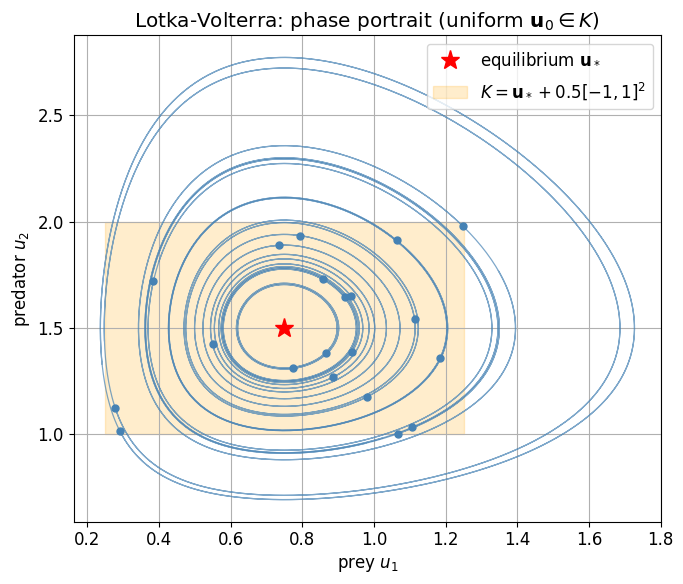

In [4]:
lv     = LotkaVolterra(alpha=alpha, beta=beta, gamma=gamma, delta=delta, T=T)
u_eq   = np.array([gamma / delta, alpha / beta])
t_fine = np.linspace(0., T * 4, 800)

n_vis   = 20
u0s_vis = u_eq + r * rng.uniform(-1., 1., (n_vis, 2))

fig, ax = plt.subplots(figsize=(7, 6))
for u0 in u0s_vis:
    traj = lv(u0, t_eval=t_fine)
    ax.plot(traj[:, 0], traj[:, 1], color='steelblue', lw=0.9, alpha=0.7)
    ax.plot(u0[0], u0[1], 'o', color='steelblue', ms=5)

ax.plot(*u_eq, 'r*', ms=14, label=r'equilibrium $\mathbf{u}_*$', zorder=5)
rect = plt.Rectangle(u_eq - r, 2. * r, 2. * r,
                     fill=True, alpha=0.2, color='orange',
                     label=rf'$K = \mathbf{{u}}_* + {r}[-1,1]^2$')
ax.add_patch(rect)
ax.set_xlabel('prey $u_1$'); ax.set_ylabel('predator $u_2$')
ax.set_title(r'Lotka-Volterra: phase portrait (uniform $\mathbf{u}_0 \in K$)')
ax.legend(); ax.grid(); plt.tight_layout()
plt.show()

## 2. The Solution Operator

We visualise $S(T) : K \to \mathbb{R}^2$ by evaluating it on a fine grid of initial
conditions inside $K$.

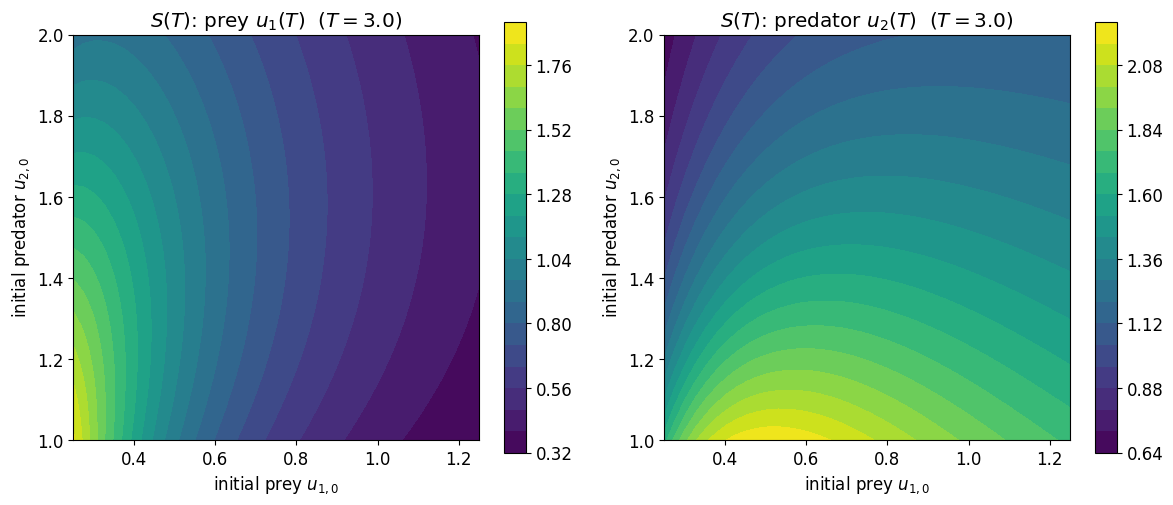

In [5]:
n_grid  = 40
u10_vals = np.linspace(u_eq[0] - r, u_eq[0] + r, n_grid)
u20_vals = np.linspace(u_eq[1] - r, u_eq[1] + r, n_grid)
U10, U20  = np.meshgrid(u10_vals, u20_vals)
U1T      = np.zeros_like(U10)
U2T      = np.zeros_like(U20)

for i in range(n_grid):
    for j in range(n_grid):
        sol        = lv(np.array([U10[i, j], U20[i, j]]))
        U1T[i, j]   = sol[0]
        U2T[i, j]   = sol[1]

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, Z, label in zip(axs, [U1T, U2T], ['prey $u_1(T)$', 'predator $u_2(T)$']):
    im = ax.contourf(U10, U20, Z, levels=20, cmap='viridis')
    fig.colorbar(im, ax=ax)
    ax.set_xlabel('initial prey $u_{1,0}$'); ax.set_ylabel('initial predator $u_{2,0}$')
    ax.set_title(f'$S(T)$: {label}  ($T = {T}$)')
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()

## 3. Test Data

We draw $n_\mathrm{test}$ parameter vectors $\bar{\mathbf{x}} \sim \mathrm{Uniform}([-1,1]^2)$,
convert to initial conditions $\mathbf{u}_0 = \mathbf{u}_* + r\bar{\mathbf{x}}$, and solve the IVP
for each.  These pairs $(\bar{\mathbf{x}}, \mathbf{u}(T))$ form the shared test set used to
evaluate all surrogates.

In [6]:
xb_test = rng.uniform(-1., 1., (n_test, 2))
u_test = np.array([lv(u_eq + r * xb) for xb in xb_test])

print(f'Test set: xb shape {xb_test.shape},  u shape {u_test.shape}')

Test set: xb shape (200, 2),  u shape (200, 2)


## 4. Sparse Grid Interpolation

For the 2-dimensional parameter domain $[-1,1]^2$ we build a Smolyak interpolant
with **Leja nodes**.  Since the two parameter components carry equal weight
(there is no preferred direction in the $(x_0, y_0)$ plane), we use **isotropic** weights
$k_1 = k_2 = 1$.

Because $S(T)$ is real-analytic on $K$ (Theorem 2.4), the interpolation error decays
**exponentially** in the number of collocation nodes $|\Lambda|$.

In [7]:
node_gen = nodes.Leja(dim=2)
k        = [1., 1.]   # isotropic: both parameter dimensions are equivalent

def target(x):
    """ Single evaluation: xb -> u(T). """
    return lv(u_eq + r * np.array(x))

n_targets = np.unique(np.round(np.geomspace(5, 500, 9)).astype(int))
f_evals   = None
ip_ns     = []
ip_errs   = []

for n_target in n_targets:
    t_thresh = indices.find_approximate_threshold(k, int(n_target), node_gen.is_nested)
    ip       = SmolyakBarycentricInterpolator(node_gen=node_gen, k=k, d_out=2, t=t_thresh)
    f_evals  = ip.set_f(f=target, f_evals=f_evals)
    u_pred   = np.array(ip(xb_test))
    ip_ns.append(ip.n_f_evals)
    ip_errs.append(error.l2_rel(u_test, u_pred))
    print(f'  nodes={ip.n_f_evals:4d}  error={ip_errs[-1]:.2e}')

ip_ns   = np.array(ip_ns)
ip_errs = np.array(ip_errs)

  nodes=   6  error=7.05e-02
  nodes=  10  error=3.55e-02
  nodes=  21  error=1.07e-02
  nodes=  28  error=4.72e-03
  nodes=  45  error=6.93e-04
  nodes=  78  error=1.07e-04
  nodes= 153  error=1.16e-06
  nodes= 300  error=4.42e-09
  nodes= 496  error=1.22e-09


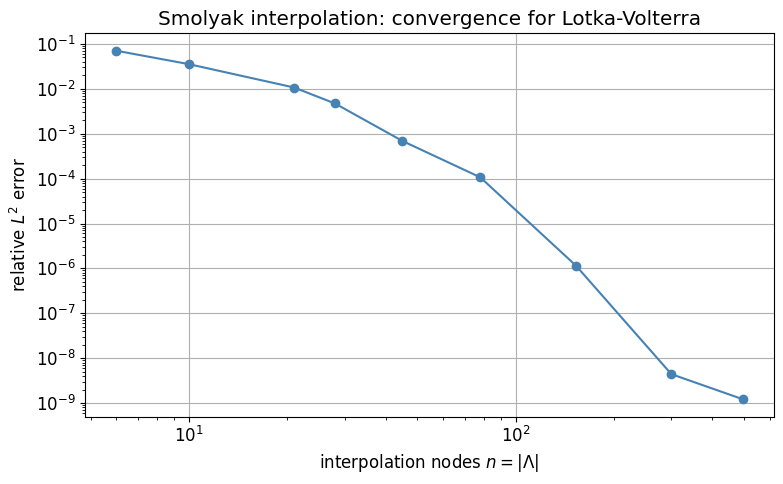

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(ip_ns, ip_errs, marker='o', color='steelblue')
ax.set_xlabel(r'interpolation nodes $n=|\Lambda|$'); ax.set_ylabel('relative $L^2$ error')
ax.set_title('Smolyak interpolation: convergence for Lotka-Volterra')
ax.grid(); plt.tight_layout()
plt.show()

## 5. Feedforward Network

In the diffusion setting, a PCA output decoder was used to compress the function-valued
output before learning in the latent space.  Here the output $\mathbf{u}(T) \in \mathbb{R}^2$
requires no compression, so a feedforward network directly approximates
$$
  g_{\boldsymbol{\theta}} : [-1,1]^2 \to \mathbb{R}^2,
  \quad \bar{\mathbf{x}} \mapsto S(T)(\mathbf{u}_* + r\bar{\mathbf{x}}).
$$
The architecture and training procedure are otherwise identical to the diffusion case.

We generate $n_\mathrm{max}$ training pairs by drawing $\bar{\mathbf{x}} \sim \mathrm{Uniform}([-1,1]^2)$
and solving the IVP for each.


In [9]:
xb_all = rng.uniform(-1., 1., (n_max, 2))
u_all = np.array([lv(u_eq + r * xb) for xb in xb_all])

print(f'Training set: xb shape {xb_all.shape},  u shape {u_all.shape}')

Training set: xb shape (1000, 2),  u shape (1000, 2)


### 5.1 Learning Curve

We first train a single network on $n = 500$ samples to verify that training converges.

Training (n=500, 500 epochs):  8s


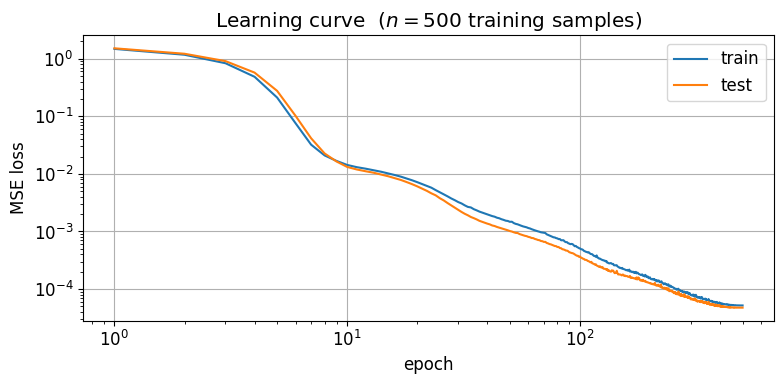

In [10]:
n_train_ex = 500

net_ex  = FFN(2, 2, layers)
history = net_ex.train({'x': xb_all[:n_train_ex], 'y': u_all[:n_train_ex]},
                       {'x': xb_test,            'y': u_test},
                       n_epochs=n_epochs)

fig, ax = plt.subplots(figsize=(8, 4))
epochs  = np.arange(1, n_epochs + 1)
ax.loglog(epochs, history['train'], label='train')
ax.loglog(epochs, history['test'],  label='test')
ax.set_xlabel('epoch'); ax.set_ylabel('MSE loss')
ax.set_title(f'Learning curve  ($n = {n_train_ex}$ training samples)')
ax.legend(); ax.grid(); plt.tight_layout()
plt.show()

### 5.2 Convergence with Training Data Size

In [11]:
n_trains = [20, 50, 100, 200, 500, 1000]
nn_errs  = []

for n_train in n_trains:
    net = FFN(2, 2, layers)
    net.train({'x': xb_all[:n_train], 'y': u_all[:n_train]},
              {'x': xb_test,         'y': u_test},
              n_epochs=n_epochs)
    u_pred = net.forward(xb_test)
    nn_errs.append(error.l2_rel(u_test, u_pred))
    print(f'n_train={n_train:5d}  error={nn_errs[-1]:.2e}')

Training (n=20, 500 epochs):  2s
n_train=   20  error=7.03e-02
Training (n=50, 500 epochs):  2s
n_train=   50  error=4.80e-02
Training (n=100, 500 epochs):  4s
n_train=  100  error=2.58e-02
Training (n=200, 500 epochs):  7s
n_train=  200  error=1.66e-02
Training (n=500, 500 epochs):  12s
n_train=  500  error=5.69e-03
Training (n=1000, 500 epochs):  24s
n_train= 1000  error=2.01e-03


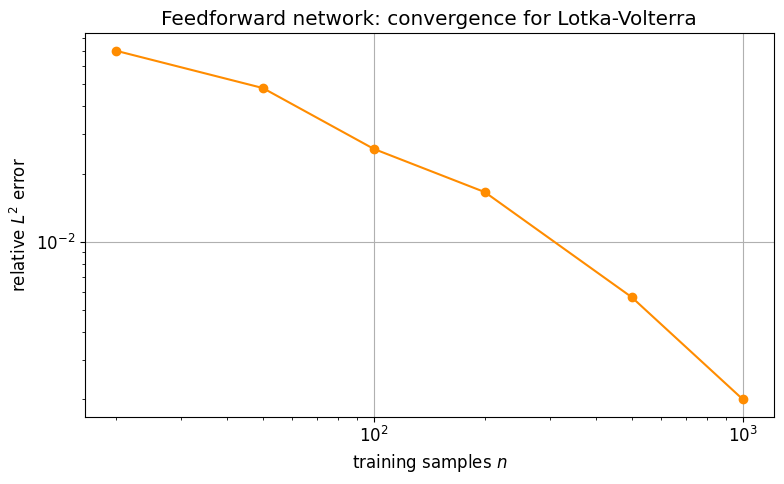

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(n_trains, nn_errs, marker='o', color='darkorange')
ax.set_xlabel('training samples $n$'); ax.set_ylabel('relative $L^2$ error')
ax.set_title('Feedforward network: convergence for Lotka-Volterra')
ax.grid(); plt.tight_layout()
plt.show()

## 6. Comparison

Both surrogates are plotted against their respective evaluation counts: number of collocation
nodes $|\Lambda|$ for the interpolant, and number of training samples $n$ for the feedforward network.
Both quantities equal the number of IVP solves required to build the surrogate.

While the feedforward network converges at an **algebraic** rate, sparse-grid interpolation converges **exponentially** as predicted by Theorem 2.5, reaching near-machine-precision accuracy with a few hundred nodes.

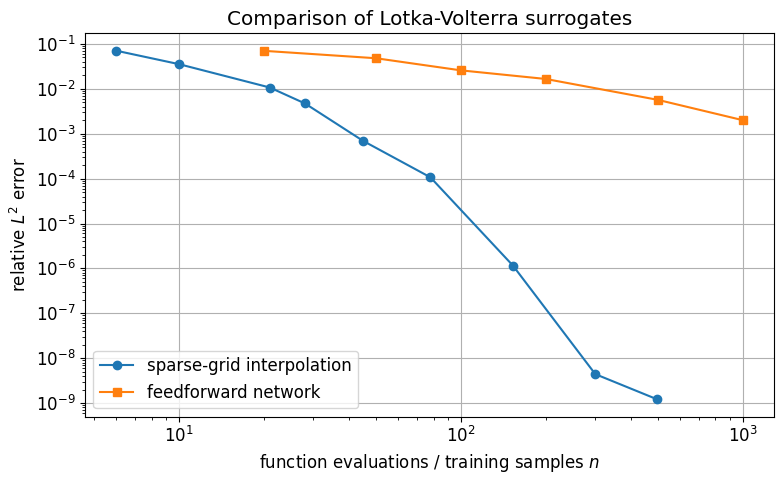

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(ip_ns,    ip_errs, marker='o', label='sparse-grid interpolation')
ax.loglog(n_trains, nn_errs, marker='s', label='feedforward network')
ax.set_xlabel(r'function evaluations / training samples $n$'); ax.set_ylabel('relative $L^2$ error')
ax.set_title('Comparison of Lotka-Volterra surrogates')
ax.legend(); ax.grid(); plt.tight_layout()
plt.show()